# The information–description-length front

Every model in this series was scored the same way — information in bits about the measured tier, $H(T) - \text{log-loss}$ of a calibrated tier distribution, on the same three kinds of split — and each notebook also declared, before fitting, how long its model is: one count of *the numbers needed to write the model down*. This notebook puts them on one chart: information against length, per split scheme. The chart answers the question the series was built for: **how many bits does a model a person can read in full carry, and what does each bit cost in model size?**

The length axis is honest but rough. A number in an equation, a threshold in a tree, a bin in a shape function and a stored training compound are not equally hard to read; the count puts them on one scale so the families can be drawn together, and the reading below weighs them separately. The forest's and the neighbour models' lengths are reported in the same units and marked as unreadable: they are the reference for what the length buys when readability is not required.

Sources: `data/aqsoldb_front_*.csv`, one file per notebook — [06_knn.ipynb](06_knn.ipynb) (neighbours and the forest), [07_additive.ipynb](07_additive.ipynb) (EBMs), [08_equations.ipynb](08_equations.ipynb) (Delaney's line, its refits, PySR), [09_trees_and_rules.ipynb](09_trees_and_rules.ipynb) (GOSDT, CORELS). The forest on the 152 descriptors appears in three of those files under three names and is one model; it is drawn once. The repeat-measurement benchmark, 0.963 bits on compounds with 2+ unflagged votes, is the horizontal reference; the tier entropy $H(T)$, printed below, is the unreachable ceiling and lies off the chart.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
from aqsoldb_harness import entropy  # noqa: E402

SAME_MODEL = {"random forest on descriptors": "random forest, RDKit, one per group (152)", "random forest, 4 classes": "random forest, RDKit, one per group (152)"}
SHORT = {  # chart labels
    "Delaney's equation (published)": "Delaney", "least squares refit of ESOL's form": "least squares, ESOL form", "Huber refit of ESOL's form": "Huber, ESOL form",
    "PySR, ESOL (4)": "PySR, ESOL 4", "PySR, top 8 by EBM importance": "PySR, top 8", "GOSDT trees (λ_reg = 0.005)": "GOSDT", "CORELS rule lists (λ_reg = 0.005)": "CORELS",
    "EBM, main effects, ESOL (4)": "EBM, ESOL 4", "EBM, 5 pairs, ESOL (4)": "EBM + 5 pairs, ESOL 4", "EBM, main effects, RDKit, one per group (152)": "EBM, 152",
    "EBM, 20 pairs, RDKit, one per group (152)": "EBM + 20 pairs, 152", "kNN on Morgan counts, radius 3 (k = 20)": "kNN, Morgan r3", "kNN on Morgan counts, radius 9 (k = 20)": "kNN, Morgan r9",
    "kNN on descriptors (k = 20)": "kNN, descriptors", "kNN on MAP4 (k = 10)": "kNN, MAP4", "random forest, RDKit, one per group (152)": "forest, 152",
    "random forest, top 8 by EBM importance": "forest, top 8", "random forest, ESOL (4)": "forest, ESOL 4",
}

files = sorted(f for f in (ROOT / "data").glob("aqsoldb_front_*.csv") if "continuous" not in f.name)  # the continuous notebook scores a different target
front = pd.concat([pd.read_csv(f).assign(notebook=f.stem.replace("aqsoldb_front_", "")) for f in files], ignore_index=True)
front["model"] = front["model"].replace(SAME_MODEL)
front = front.sort_values("notebook").drop_duplicates(subset=["model", "scheme", "subset"], keep="last")  # one row per model: the additive notebook's forest fit
front["label"] = front["model"].map(SHORT).fillna(front["model"])
votes = pd.read_csv(ROOT / "data" / "aqsoldb_tiers.csv")
values = votes[votes["weight"] > 0]
H = entropy(np.bincount(values["tier"], weights=values["weight"]) / values["weight"].sum())
BENCHMARK = 0.963
print(f"{len(files)} files, {front['model'].nunique()} models; H(T) = {H:.3f} bits (off the chart)")
front.pivot_table(index=["family", "model", "inputs"], columns=["scheme", "subset"], values="information (bits)").round(3)

4 files, 18 models; H(T) = 1.951 bits (off the chart)


scheme                                                                                      cluster cross-validation  \
subset                                                                                            all test compounds   
family             model                                         inputs                                                
EBM                EBM, 20 pairs, RDKit, one per group (152)     RDKit, one per group (152)                    0.907   
                   EBM, 5 pairs, ESOL (4)                        ESOL (4)                                      0.784   
                   EBM, main effects, ESOL (4)                   ESOL (4)                                      0.714   
                   EBM, main effects, RDKit, one per group (152) RDKit, one per group (152)                    0.895   
equation           Delaney's equation (published)                ESOL (4)                                      0.588   
                   Huber refit of ESOL's form                    ESOL (4)                                      0.544   
                   PySR, ESOL (4)                                ESOL (4)                                      0.594   
                   PySR, top 8 by EBM importance                 top 8 by EBM importance                       0.621   
                   least squares refit of ESOL's form            ESOL (4)                                      0.436   
nearest neighbours kNN on MAP4 (k = 10)                          MAP4                                          0.567   
                   kNN on Morgan counts, radius 3 (k = 20)       Morgan counts, radius 3                       0.637   
                   kNN on Morgan counts, radius 9 (k = 20)       Morgan counts, radius 9                       0.621   
                   kNN on descriptors (k = 20)                   descriptors                                   0.781   
random forest      random forest, ESOL (4)                       ESOL (4)                                      0.725   
                   random forest, RDKit, one per group (152)     RDKit, one per group (152)                    0.941   
                   random forest, top 8 by EBM importance        top 8 by EBM importance                       0.896   
rule list          CORELS rule lists (λ_reg = 0.005)             RDKit, one per group (152)                    0.543   
tree               GOSDT trees (λ_reg = 0.005)                   RDKit, one per group (152)                    0.546   

scheme                                                                                                                              \
subset                                                                                      test compounds with 2+ unflagged votes   
family             model                                         inputs                                                              
EBM                EBM, 20 pairs, RDKit, one per group (152)     RDKit, one per group (152)                                  0.893   
                   EBM, 5 pairs, ESOL (4)                        ESOL (4)                                                    0.792   
                   EBM, main effects, ESOL (4)                   ESOL (4)                                                    0.708   
                   EBM, main effects, RDKit, one per group (152) RDKit, one per group (152)                                  0.884   
equation           Delaney's equation (published)                ESOL (4)                                                    0.542   
                   Huber refit of ESOL's form                    ESOL (4)                                                    0.504   
                   PySR, ESOL (4)                                ESOL (4)                                                    0.570   
                   PySR, top 8 by EBM importance                 top 8 by EBM importance                                     0.601   
     

## The chart

Left: random cross-validation, all test compounds — the familiar-chemistry score. Right: cluster cross-validation — unfamiliar chemistry. Filled markers are models a person can read in full; open markers are not. The vertical bars are the standard error over splits. The x-axis is logarithmic: the lengths span six orders of magnitude. Labels in the same decade are stacked in order of information.

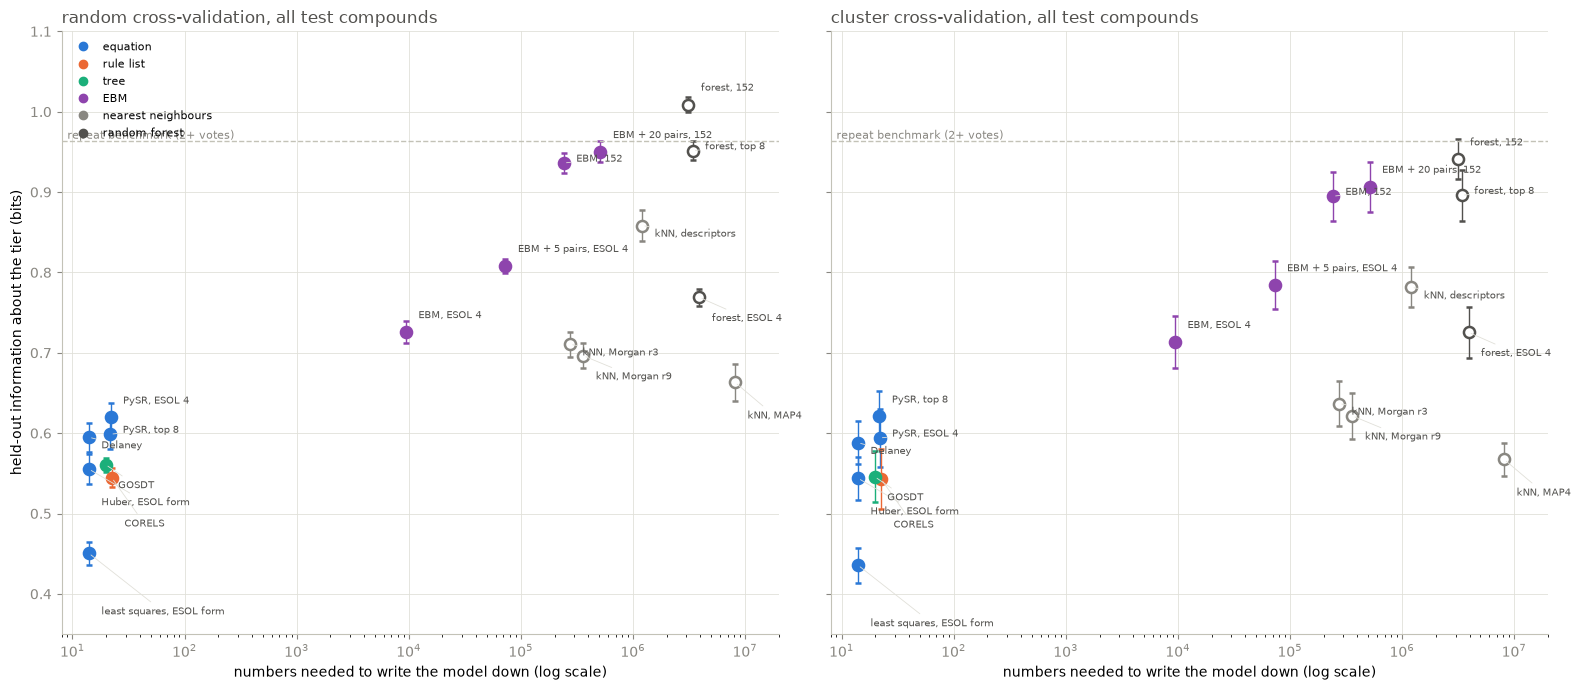

In [2]:
INK, MUTED, GRID, AXIS = "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
FAMILY_COLORS = {"equation": "#2a78d6", "rule list": "#eb6834", "tree": "#1baf7a", "EBM": "#8e44ad", "nearest neighbours": "#898781", "random forest": "#52514e"}
SUBSET = "all test compounds"


def style(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(AXIS)
    ax.tick_params(colors=MUTED)
    ax.grid(color=GRID, lw=0.6)
    ax.set_axisbelow(True)


fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)
for ax, scheme in zip(axes, ["random cross-validation", "cluster cross-validation"]):
    d = front[(front["scheme"] == scheme) & (front["subset"] == SUBSET)].dropna(subset=["numbers to write it down"]).copy()
    d["decade"] = np.floor(np.log10(d["numbers to write it down"])).astype(int)
    d["stack"] = d.groupby("decade")["information (bits)"].rank(ascending=False).astype(int) - 1
    for _, r in d.iterrows():
        color = FAMILY_COLORS.get(r["family"], INK)
        ax.errorbar(r["numbers to write it down"], r["information (bits)"], yerr=r["spread"], fmt="o", ms=8, color=color,
                    mfc=color if r["readable"] else "white", mew=1.8, ecolor=color, elinewidth=1, capsize=2)
        ax.annotate(r["label"], (r["numbers to write it down"], r["information (bits)"]), xytext=(9, 10 - 9 * r["stack"]), textcoords="offset points",
                    fontsize=7.5, color=INK, arrowprops=dict(arrowstyle="-", color=GRID, lw=0.6) if r["stack"] else None)
    ax.axhline(BENCHMARK, color=AXIS, lw=1, ls="--")
    ax.text(9, BENCHMARK, "repeat benchmark (2+ votes)", color=MUTED, fontsize=8, va="bottom", ha="left")
    ax.set_xscale("log")
    ax.set_xlim(8, 2e7)
    ax.set_ylim(0.35, 1.1)
    ax.set_title(f"{scheme}, {SUBSET}", loc="left", color=INK)
    ax.set_xlabel("numbers needed to write the model down (log scale)")
    style(ax)
axes[0].set_ylabel("held-out information about the tier (bits)")
handles = [plt.Line2D([], [], marker="o", ls="", color=c, mfc=c, label=f) for f, c in FAMILY_COLORS.items()]
axes[0].legend(handles=handles, frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()

## The front, as a table

Models sorted by length (rounded to two significant figures, so models of the same size compete directly), with the information on each scheme (all test compounds). A model is **on the front** if no model of the same or shorter length has higher random-CV information. "Bits per decade" is the slope between consecutive front points: what the extra length bought.

In [3]:
wide = front[front["subset"] == SUBSET].pivot_table(index=["model", "family", "readable", "numbers to write it down"], columns="scheme", values="information (bits)").reset_index()
wide = wide.dropna(subset=["numbers to write it down"])
wide["length (2 s.f.)"] = wide["numbers to write it down"].apply(lambda n: float(f"{n:.2g}"))
wide = wide.sort_values(["length (2 s.f.)", "random cross-validation"], ascending=[True, False])
best_so_far = -np.inf
on_front = []
for info in wide["random cross-validation"]:
    on_front.append(info > best_so_far)
    best_so_far = max(best_so_far, info)
wide["on the front"] = on_front
f = wide[wide["on the front"]]
wide["bits per decade of length (front steps)"] = (f["random cross-validation"].diff() / np.log10(f["length (2 s.f.)"]).diff()).reindex(wide.index)
pd.set_option("display.width", 200)
wide.drop(columns="numbers to write it down").set_index("model").round(3)

scheme,family,readable,cluster cross-validation,learning to split,random cross-validation,length (2 s.f.),on the front,bits per decade of length (front steps)
model,,,,,,,,
Delaney's equation (published),equation,True,0.588,-0.451,0.595,14.0,True,NaN
Huber refit of ESOL's form,equation,True,0.544,-0.514,0.555,14.0,False,NaN
least squares refit of ESOL's form,equation,True,0.436,-0.445,0.451,14.0,False,NaN
GOSDT trees (λ_reg = 0.005),tree,True,0.546,-0.753,0.561,20.0,False,NaN
"PySR, ESOL (4)",equation,True,0.594,-0.536,0.619,22.0,True,0.125
"PySR, top 8 by EBM importance",equation,True,0.621,-0.481,0.599,22.0,False,NaN
CORELS rule lists (λ_reg = 0.005),rule list,True,0.543,-0.732,0.544,22.0,False,NaN
"EBM, main effects, ESOL (4)",EBM,True,0.714,-0.877,0.726,9400.0,True,0.040
"EBM, 5 pairs, ESOL (4)",EBM,True,0.784,-1.046,0.808,73000.0,True,0.092


## Reading

1. **The front is readable almost to the top.** Every point on the random-CV front but the last is a model a person can read in full: Delaney's line (14 numbers, 0.595 bits), PySR's equation (22, 0.619), the additive model on ESOL's four inputs (9,400, 0.726), with five pairs (73,000, 0.808), on the 152 descriptors (240,000, 0.936) and with twenty pairs (510,000, 0.950), and then the forest (3.1 million, 1.009). The last 0.06 bits cost a factor of six in length and all of the readability. Nothing unreadable other than the forest is on the front: every neighbour model sits below an EBM that is shorter (kNN on descriptors, 0.858 bits at 1.2 million numbers, against the main-effects EBM's 0.936 at 240,000), and the forests on four and eight inputs are matched or beaten by EBMs a hundredth to a tenth their length.

2. **Three plateaus, and where the bits are cheap.** The models cluster at three lengths. At 14–22 numbers — an equation, a pair of trees, a pair of rule lists — the information is 0.54–0.62 bits whatever the family; the best of them, PySR's equation, carries 61% of the forest's information in a line a person can read in a minute. Between 22 and 9,400 numbers the front gains only 0.107 bits over 2.6 decades (0.04 bits per decade): a longer equation or tree is not what buys the next bits, more inputs with their own curves is. The steepest step on the front is from four inputs to 152 for the additive model, 0.13 bits for half a decade (0.25 bits per decade); the two interaction steps are the flattest (0.04 and 0.09 bits per decade). From there to the forest is 0.075 bits per decade, the slope of giving up readability.

3. **Unfamiliar chemistry keeps the order and shrinks the gaps.** On cluster splits every model loses, but not equally: the forest loses 0.07 bits, the 152-descriptor EBMs 0.04, the equations at most 0.03 (one gains), the trees 0.015. The front keeps its shape, the forest's lead over the 20-pair EBM narrows to 0.03 bits, and PySR's eight-input equation becomes the best 22-number model (0.621). The learned splits reverse the order outright: the equations are the least over-confident models there (−0.45 to −0.54 bits), then the forest (−0.61), the trees (−0.73 and −0.75), the neighbours (−0.8 to −1.0) and the EBMs last (−0.88 to −1.62). The shortest models extrapolate with the least false confidence; that is a second argument for them that the random-CV chart does not show.

4. **What the length unit hides.** The count is honest arithmetic but not equal effort. Twenty-two numbers in an equation or twenty thresholds and leaves in two trees are read in a minute; the 9,400 numbers of the four-input EBM are four curves, read in a minute too; the 240,000 of the 152-descriptor EBM are 152 curves of which 82 carry 90% of the importance, an afternoon; the twenty pair surfaces add an hour; the forest is never read. On that scale the chart's middle is flatter than it looks — the four-curve EBM at 0.726 bits is as readable as the equations and carries 0.1 bit more — and the honest summary is: **a minute of reading buys 0.6–0.73 bits, an afternoon buys 0.94–0.95, and giving up reading altogether buys 0.06 more.** The repeat-measurement benchmark (0.963 bits on compounds measured twice or more) sits between the afternoon and the forest: a model a person can read in full comes within a few hundredths of a bit of what a second measurement would tell you (0.950 against 0.963 on all compounds; 0.928 on the benchmark's own population, from the table at the top).

5. **One number to carry away.** Every family found the same first fact in its own language — the EBM's logP sigmoid, the equation's $\log(MW + (\log P - c)^4)$, the tree's single question *logP ≤ 2.76* — and that fact is worth about 0.55 bits. Everything after it, from 0.55 to 1.01 bits, is the size-and-shape detail that the longer models hold and the shortest cannot: that is the information in this data set that is not logP.